# TP3 - Análisis de las tablas

La idea es mirar primero qué información tenemos en cada tabla y después ver cómo relacionarlas sin usar datos del futuro. La unidad principal va a ser la solicitud: cuando terminemos de preparar los datos tiene que quedar una fila por solicitud.

In [65]:
import pandas as pd
import numpy as np

solicitudes_train = pd.read_csv("data/solicitudes_train.csv")
comportamiento_bancario = pd.read_csv("data/comportamiento_bancario.csv")

## Solicitudes de préstamos

Cada fila representa una solicitud. `ID_Solicitud` identifica la solicitud y `ID_Usuario` nos va a permitir relacionarla con el historial bancario.

In [66]:
solicitudes_train.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final
0,1,12698,7900,0.2333,4461,Consumo,2025-04,1
1,2,20744,17400,0.2507,3889,Vivienda,2025-12,1
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06,0
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07,1
4,5,24719,6600,0.2314,3357,Otros,2025-01,1


In [67]:
solicitudes_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32416 entries, 0 to 32415
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Solicitud      32416 non-null  int64  
 1   ID_Usuario        32416 non-null  int64  
 2   Monto_Solicitado  32416 non-null  int64  
 3   Tasa_Interes      32416 non-null  float64
 4   Ingreso_Mensual   32416 non-null  int64  
 5   Motivo_Prestamo   32416 non-null  str    
 6   Fecha_Solicitud   32416 non-null  str    
 7   Estado_Final      32416 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 2.4 MB


Primero revisamos la cantidad de usuarios, si hay duplicados o datos faltantes y qué período cubren las solicitudes. También pasamos la fecha al tipo correcto para poder compararla más adelante con los meses del historial bancario.

In [68]:
solicitudes_train["Fecha_Solicitud"] = pd.to_datetime(
    solicitudes_train["Fecha_Solicitud"]
)

print("Usuarios distintos:", solicitudes_train["ID_Usuario"].nunique())

print("Filas duplicadas:", solicitudes_train.duplicated().sum())


print("\nPeríodo:", solicitudes_train["Fecha_Solicitud"].min().date(),
      "a", solicitudes_train["Fecha_Solicitud"].max().date())

print("Máximo de solicitudes de un usuario:",
      solicitudes_train.groupby("ID_Usuario").size().max())

Usuarios distintos: 18548
Filas duplicadas: 0

Período: 2025-01-01 a 2025-12-01
Máximo de solicitudes de un usuario: 8


### Variables numéricas

idea general de los montos solicitados, los ingresos y las tasas de interés.

In [69]:
solicitudes_train[[
    "Monto_Solicitado",
    "Ingreso_Mensual",
    "Tasa_Interes"
]].describe()

,Monto_Solicitado,Ingreso_Mensual,Tasa_Interes
count,32416.000000,32416.000000,32416.000000
mean,14290.097483,4214.475938,0.259580
std,12995.295179,2498.904569,0.032333
min,500.000000,353.000000,0.147600
25%,5700.000000,2481.000000,0.237300
50%,10200.000000,3621.000000,0.258300
75%,18100.000000,5276.000000,0.280600
max,70000.000000,22000.000000,0.379900


### Relación entre el préstamo y el ingreso

comparando el ingreso mensual de la persona con el monto del prestamos sacamos un ratio, entre más alto significa que el préstamo representa varios meses de ingreso y podría ser más difícil de pagar.

In [70]:
solicitudes_train["ratio_prestamo_ingreso"] = (
    solicitudes_train["Monto_Solicitado"]
    / solicitudes_train["Ingreso_Mensual"]
)

solicitudes_train[[
    "ID_Solicitud",
    "ID_Usuario",
    "Monto_Solicitado",
    "Ingreso_Mensual",
    "ratio_prestamo_ingreso"
]]

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Ingreso_Mensual,ratio_prestamo_ingreso
0,1,12698,7900,4461,1.770903
1,2,20744,17400,3889,4.474158
2,3,6830,8600,4035,2.131351
3,4,5722,13300,4018,3.310105
4,5,24719,6600,3357,1.966041
...,...,...,...,...,...
32411,32412,22337,38600,7654,5.043115
32412,32413,15817,4700,1388,3.386167
32413,32414,330,5000,2445,2.044990
32414,32415,2907,28600,8412,3.399905


### Estado final

`Estado_Final` es lo que más adelante queremos predecir: 1 significa que el préstamo fue pagado y 0 que terminó en default. vemos si las dos clases están equilibradas.

In [71]:
solicitudes_train["Estado_Final"].value_counts(normalize=True).sort_index() * 100

Estado_Final
0    15.951999
1    84.048001
Name: proportion, dtype: float64

### Motivo del préstamo

podemos mirar por tipo de categoria que "porcentaje" de pago tiene, capaz no cambia mucho pero bueno, todo sirve

In [72]:
porcentaje_pago_por_motivo = (
    solicitudes_train.groupby("Motivo_Prestamo")["Estado_Final"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

porcentaje_pago_por_motivo

Motivo_Prestamo
Educacion    85.990712
Vivienda     85.939941
Salud        85.610264
Consumo      83.677754
Otros        82.909640
Vehiculo     82.612782
Negocio      80.626672
Name: Estado_Final, dtype: float64

### Tasa de interés

La tasa promedio cambia poco entre los préstamos pagados y los que terminaron en default, por sí sola tal vez no aporta mucho, pero la vamos a necesitar para calcular la ganancia esperada.

In [73]:
solicitudes_train.groupby("Estado_Final")["Tasa_Interes"].mean().sort_index()

Estado_Final
0    0.267905
1    0.258000
Name: Tasa_Interes, dtype: float64

## Comportamiento bancario
esta tabla cada fila representa un mes de un usuario. Por eso tiene muchas más filas que la tabla de solicitudes.

In [74]:
comportamiento_bancario.head()

,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,2024-01,12768.11,3
1,1,2024-02,15817.67,3
2,1,2024-03,13138.66,0
3,1,2024-04,19453.13,0
4,1,2024-05,14943.44,59


In [75]:
comportamiento_bancario.info()

<class 'pandas.DataFrame'>
RangeIndex: 661139 entries, 0 to 661138
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID_Usuario                661139 non-null  int64  
 1   Mes_Referencia            661139 non-null  str    
 2   Saldo_Promedio_Mensual    661139 non-null  float64
 3   Dias_Atraso_Otras_Deudas  661139 non-null  int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 24.6 MB


Pasamos `Mes_Referencia` a fecha y revisamos usuarios, duplicados, valores faltantes y cantidad de meses disponibles.

In [76]:
comportamiento_bancario["Mes_Referencia"] = pd.to_datetime(
    comportamiento_bancario["Mes_Referencia"]
)

print("Usuarios distintos:", comportamiento_bancario["ID_Usuario"].nunique())
print("Período:", comportamiento_bancario["Mes_Referencia"].min().date(),
      "a", comportamiento_bancario["Mes_Referencia"].max().date())

meses_por_usuario = comportamiento_bancario.groupby(
    "ID_Usuario"
)["Mes_Referencia"].nunique()

print("\nMeses disponibles por usuario:")
display(meses_por_usuario.describe().round(2))

Usuarios distintos: 28993
Período: 2024-01-01 a 2025-12-01

Meses disponibles por usuario:


count    28993.00
mean        22.80
std          1.07
min         17.00
25%         22.00
50%         23.00
75%         24.00
max         24.00
Name: Mes_Referencia, dtype: float64

### Saldos y atrasos

`Saldo_Promedio_Mensual` no es el sueldo de la persona: es el saldo promedio que mantuvo en la cuenta durante ese mes. Nos puede servir para ver su situación y si viene mejorando o empeorando. Los días de atraso muestran cómo se comportó con otras deudas.

In [77]:
comportamiento_bancario[[
    "Saldo_Promedio_Mensual",
    "Dias_Atraso_Otras_Deudas"
]].describe()

,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
count,661139.000000,661139.000000
mean,5463.296614,8.950755
std,5473.861364,13.199638
min,3.300000,0.000000
25%,2061.955000,1.000000
50%,3974.280000,5.000000
75%,7082.925000,10.000000
max,165915.350000,90.000000


Como exploración podemos resumir el historial completo de cada usuario para ver qué características podrían servir: saldo promedio, saldo inicial, saldo final, cambio del saldo y atrasos. Este resumen todavía no se usa para entrenar porque incluye meses que podrían ser posteriores a una solicitud.

In [78]:
banco_ordenado = comportamiento_bancario.sort_values(
    ["ID_Usuario", "Mes_Referencia"]
)

resumen_exploratorio_banco = banco_ordenado.groupby("ID_Usuario").agg(
    meses_disponibles=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
)

resumen_exploratorio_banco["cambio_saldo"] = (
    resumen_exploratorio_banco["saldo_final"]
    - resumen_exploratorio_banco["saldo_inicial"]
)

resumen_exploratorio_banco.head()

,meses_disponibles,saldo_promedio,saldo_inicial,saldo_final,atraso_promedio,atraso_maximo,cambio_saldo
ID_Usuario,,,,,,,
1,23,20017.683913,12768.11,23343.81,8.304348,59,10575.70
2,21,3781.878571,3335.41,4576.35,16.619048,67,1240.94
3,22,4577.649545,4683.17,4133.35,1.090909,4,-549.82
4,24,4992.794583,3971.51,6122.52,1.958333,18,2151.01
5,24,2556.866667,3738.41,1753.87,27.000000,70,-1984.54


## Relacionar las tablas

No podemos unir y dejar las tablas así nomás porque una solicitud se repetiría una vez por cada mes bancario del usuario. Primero hacemos esa unión para relacionar los registros, después sacamos los meses futuros y finalmente vamos a resumir el historial de cada solicitud.

### Paso 1: unir por usuario

aca van a aumentar mucho la cantidad de filas ya que cada solicitud queda repetida por todos los meses bancarios de su usuario.

In [79]:
historial_solicitudes = solicitudes_train.merge(
    comportamiento_bancario,
    on="ID_Usuario",
    how="left"
)

print("Filas de solicitudes:", len(solicitudes_train))
print("Filas después del merge:", len(historial_solicitudes))

Filas de solicitudes: 32416
Filas después del merge: 739137


### Paso 2: conservar solamente los meses anteriores

ver de usar la información que ya existía en ese momento. Si usáramos meses posteriores estaríamos mirando el futuro. Como las fechas indican solamente el mes, también dejamos afuera el mismo mes de la solicitud.

In [80]:
historial_solicitudes = historial_solicitudes[
    historial_solicitudes["Mes_Referencia"]
    < historial_solicitudes["Fecha_Solicitud"]
].copy()

print("Filas después del filtro temporal:", len(historial_solicitudes))
print("Solicitudes distintas:", historial_solicitudes["ID_Solicitud"].nunique())

Filas después del filtro temporal: 538638
Solicitudes distintas: 32416


Todavía hay varias filas por solicitud, una por cada mes anterior. El próximo paso va a ser resumir esos meses por `ID_Solicitud` para volver a tener una sola fila por préstamo.

In [81]:
historial_solicitudes

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-01-01,3712.29,2
1,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-02-01,3749.28,25
2,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-03-01,3510.29,3
3,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-04-01,3997.29,1
4,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-05-01,3304.99,7
...,...,...,...,...,...,...,...,...,...,...,...,...
739122,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-10-01,13248.54,0
739123,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-11-01,15281.30,4
739124,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-12-01,13933.95,0
739125,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2025-01-01,17164.54,0


### Paso 3: resumir el historial por solicitud

Ahora agrupamos por `ID_Solicitud`, porque un mismo usuario puede haber pedido varios préstamos en fechas distintas. Guardamos la cantidad de meses, el saldo promedio, el último saldo conocido, la evolución del saldo y el comportamiento de los atrasos.

In [82]:
historial_ordenado = historial_solicitudes.sort_values(
    ["ID_Solicitud", "Mes_Referencia"]
)

resumen_historial = historial_ordenado.groupby("ID_Solicitud").agg(
    meses_historial=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

resumen_historial.head()

,ID_Solicitud,meses_historial,saldo_promedio,saldo_inicial,saldo_final,atraso_promedio,atraso_maximo
0,1,14,3695.225714,3712.29,3352.35,4.857143,25
1,2,21,5976.456667,3807.48,5054.62,8.809524,56
2,3,15,178.574667,203.23,178.46,20.733333,57
3,4,18,7589.356667,6543.97,7372.57,0.944444,4
4,5,12,3888.616667,4848.48,2952.59,3.750000,32


### Paso 4: volver a una fila por solicitud y crear los ratios

Volvemos a unir el resumen con las solicitudes. El ratio de tendencia compara el último saldo con el primero: un valor mayor que 1 indica una suba y uno menor que 1 una baja. También comparamos el monto solicitado con el ingreso y con el saldo promedio. Las variables originales se conservan porque el ratio solo no muestra la escala de los montos.

In [83]:
datos_modelo = solicitudes_train.merge(
    resumen_historial,
    on="ID_Solicitud",
    how="left",
    validate="one_to_one"
)

saldo_inicial_seguro = datos_modelo["saldo_inicial"].mask(
    datos_modelo["saldo_inicial"].eq(0)
)
saldo_promedio_seguro = datos_modelo["saldo_promedio"].mask(
    datos_modelo["saldo_promedio"].eq(0)
)

datos_modelo["ratio_tendencia_saldo"] = (
    datos_modelo["saldo_final"] / saldo_inicial_seguro
)
datos_modelo["ratio_prestamo_ingreso"] = (
    datos_modelo["Monto_Solicitado"] / datos_modelo["Ingreso_Mensual"]
)
datos_modelo["ratio_prestamo_saldo"] = (
    datos_modelo["Monto_Solicitado"] / saldo_promedio_seguro
)

datos_modelo = datos_modelo.drop(columns="saldo_inicial")

print("Filas del dataset preparado:", len(datos_modelo))
print("Solicitudes distintas:", datos_modelo["ID_Solicitud"].nunique())
datos_modelo.head()

Filas del dataset preparado: 32416
Solicitudes distintas: 32416


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,meses_historial,saldo_promedio,saldo_final,atraso_promedio,atraso_maximo,ratio_tendencia_saldo,ratio_prestamo_saldo
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,14,3695.225714,3352.35,4.857143,25,0.903041,2.137894
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,4.474158,21,5976.456667,5054.62,8.809524,56,1.327550,2.911424
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,2.131351,15,178.574667,178.46,20.733333,57,0.878118,48.159127
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,3.310105,18,7589.356667,7372.57,0.944444,4,1.126620,1.752454
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,1.966041,12,3888.616667,2952.59,3.750000,32,0.608972,1.697262


para el modelo el objetivo va a ser Estado_Final, excluiriamos el Id_Solicitud e Id_Usuario, ver de transformar Motivo_Prestamo (que es categorica), en el tema del mes podemos verla de excluir, separar por los id de los usuarios para que no aparezcan en el entrenamiento y validacion.

In [84]:
print("Cantidad de filas:", len(datos_modelo))
print("Solicitudes distintas:", datos_modelo["ID_Solicitud"].nunique())
print("IDs repetidos:", datos_modelo["ID_Solicitud"].duplicated().sum())

Cantidad de filas: 32416
Solicitudes distintas: 32416
IDs repetidos: 0


In [85]:
datos_modelo.isnull().sum().sort_values(ascending=False)

ID_Solicitud              0
ID_Usuario                0
Monto_Solicitado          0
Tasa_Interes              0
Ingreso_Mensual           0
Motivo_Prestamo           0
Fecha_Solicitud           0
Estado_Final              0
ratio_prestamo_ingreso    0
meses_historial           0
saldo_promedio            0
saldo_final               0
atraso_promedio           0
atraso_maximo             0
ratio_tendencia_saldo     0
ratio_prestamo_saldo      0
dtype: int64

In [86]:
np.isinf(
    datos_modelo.select_dtypes(include="number")
).sum().sort_values(ascending=False)

ID_Solicitud              0
ID_Usuario                0
Monto_Solicitado          0
Tasa_Interes              0
Ingreso_Mensual           0
Estado_Final              0
ratio_prestamo_ingreso    0
meses_historial           0
saldo_promedio            0
saldo_final               0
atraso_promedio           0
atraso_maximo             0
ratio_tendencia_saldo     0
ratio_prestamo_saldo      0
dtype: int64

In [87]:
datos_modelo[[
    "ratio_prestamo_ingreso",
    "ratio_prestamo_saldo",
    "ratio_tendencia_saldo"
]].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])

,ratio_prestamo_ingreso,ratio_prestamo_saldo,ratio_tendencia_saldo
count,32416.000000,32416.000000,32416.000000
mean,3.439613,14.551608,1.105596
std,2.425354,73.067997,0.539219
min,0.123122,0.068209,0.113253
1%,0.612282,0.359758,0.324540
5%,0.964803,0.623646,0.465906
50%,2.799969,2.522912,1.002416
95%,8.166632,28.115860,2.093306
99%,12.217510,342.112035,2.960705
max,55.142018,1897.614428,8.252326


In [88]:
datos_modelo["log_ratio_prestamo_ingreso"] = np.log1p(
    datos_modelo["ratio_prestamo_ingreso"]
)

datos_modelo["log_ratio_prestamo_saldo"] = np.log1p(
    datos_modelo["ratio_prestamo_saldo"]
)

datos_modelo["log_ratio_tendencia_saldo"] = np.log(
    datos_modelo["ratio_tendencia_saldo"]
)

In [89]:
datos_modelo


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,meses_historial,saldo_promedio,saldo_final,atraso_promedio,atraso_maximo,ratio_tendencia_saldo,ratio_prestamo_saldo,log_ratio_prestamo_ingreso,log_ratio_prestamo_saldo,log_ratio_tendencia_saldo
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,14,3695.225714,3352.35,4.857143,25,0.903041,2.137894,1.019173,1.143552,-0.101987
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,4.474158,21,5976.456667,5054.62,8.809524,56,1.327550,2.911424,1.700038,1.363902,0.283335
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,2.131351,15,178.574667,178.46,20.733333,57,0.878118,48.159127,1.141464,3.895063,-0.129974
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,3.310105,18,7589.356667,7372.57,0.944444,4,1.126620,1.752454,1.460962,1.012493,0.119222
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,1.966041,12,3888.616667,2952.59,3.750000,32,0.608972,1.697262,1.087228,0.992237,-0.495983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32411,32412,22337,38600,0.2640,7654,Vivienda,2025-04-01,1,5.043115,13,10926.146154,7144.53,4.846154,38,0.599719,3.532810,1.798920,1.511342,-0.511293
32412,32413,15817,4700,0.2872,1388,Otros,2025-10-01,0,3.386167,19,504.819474,359.29,19.421053,65,0.519942,9.310259,1.478456,2.333139,-0.654039
32413,32414,330,5000,0.2699,2445,Vehiculo,2025-05-01,1,2.044990,16,2730.808125,2381.08,10.125000,15,0.767929,1.830960,1.113498,1.040616,-0.264058
32414,32415,2907,28600,0.2907,8412,Negocio,2025-02-01,1,3.399905,12,15493.373333,15278.24,4.666667,48,1.112332,1.845950,1.481583,1.045897,0.106459


grafico para ver como quedo el grafico normalizado con la funcion logaritmica

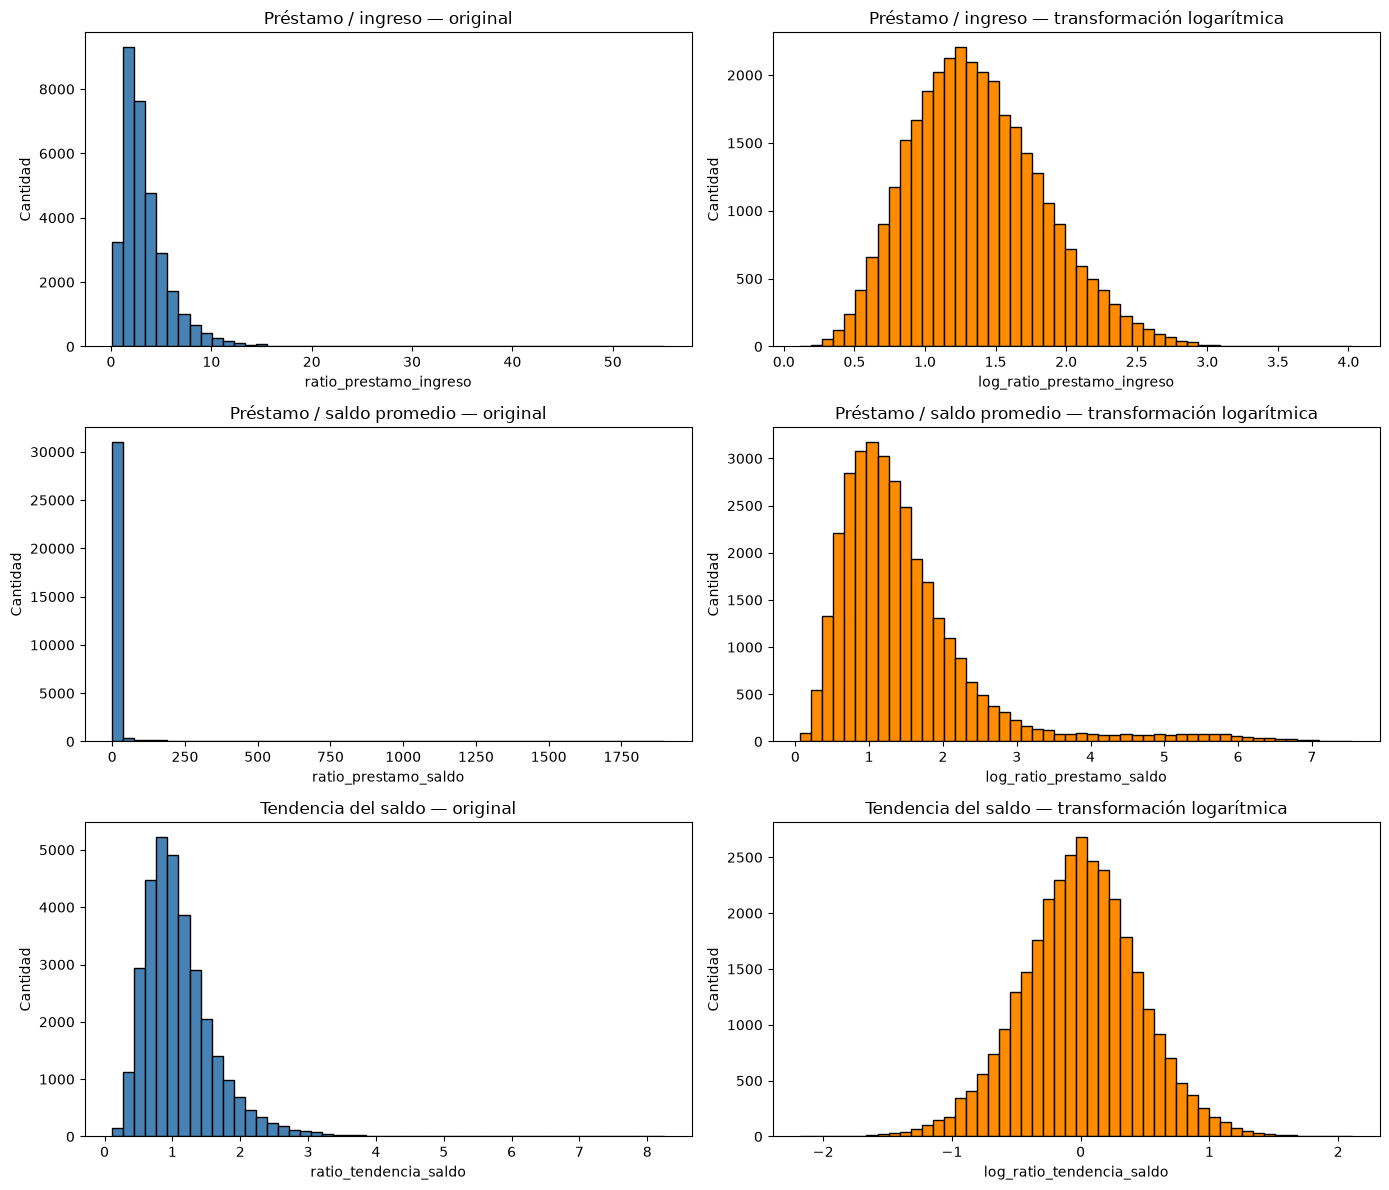

In [90]:
import matplotlib.pyplot as plt

comparaciones = [
    (
        "ratio_prestamo_ingreso",
        "log_ratio_prestamo_ingreso",
        "Préstamo / ingreso"
    ),
    (
        "ratio_prestamo_saldo",
        "log_ratio_prestamo_saldo",
        "Préstamo / saldo promedio"
    ),
    (
        "ratio_tendencia_saldo",
        "log_ratio_tendencia_saldo",
        "Tendencia del saldo"
    )
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for fila, (original, logaritmica, titulo) in enumerate(comparaciones):

    axes[fila, 0].hist(
        datos_modelo[original].dropna(),
        bins=50,
        color="steelblue",
        edgecolor="black"
    )
    axes[fila, 0].set_title(f"{titulo} — original")
    axes[fila, 0].set_xlabel(original)
    axes[fila, 0].set_ylabel("Cantidad")

    axes[fila, 1].hist(
        datos_modelo[logaritmica].dropna(),
        bins=50,
        color="darkorange",
        edgecolor="black"
    )
    axes[fila, 1].set_title(f"{titulo} — transformación logarítmica")
    axes[fila, 1].set_xlabel(logaritmica)
    axes[fila, 1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

verificar si en algun dato de registros bancarios tiene fecha igual o posterior a fecha_solicitud

In [91]:
(historial_solicitudes["Mes_Referencia"] < historial_solicitudes["Fecha_Solicitud"]).all()

np.True_

## Dataset común para comparar modelos

El dataset se divide una sola vez por ID_Usuario. Todos los modelos van a usar las mismas solicitudes de entrenamiento y validación. La codificación de Motivo_Prestamo se hará después, dentro del Pipeline de cada modelo.

In [92]:
from sklearn.model_selection import GroupShuffleSplit

columnas_excluidas = [
    "Estado_Final",
    "ID_Solicitud",
    "ID_Usuario",
    "Fecha_Solicitud",
    "ratio_prestamo_ingreso",
    "ratio_prestamo_saldo",
    "ratio_tendencia_saldo"
]

X = datos_modelo.drop(columns=columnas_excluidas).copy()
y = datos_modelo["Estado_Final"].copy()
grupos = datos_modelo["ID_Usuario"].copy()

separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

indices_train, indices_validacion = next(
    separador.split(X, y, groups=grupos)
)

X_train = X.iloc[indices_train].copy()
X_validacion = X.iloc[indices_validacion].copy()
y_train = y.iloc[indices_train].copy()
y_validacion = y.iloc[indices_validacion].copy()

validacion_completa = datos_modelo.iloc[indices_validacion].copy()

### Comprobación del split

Además de mirar el tamaño de cada conjunto, comprobamos que no haya usuarios compartidos y que la proporción de préstamos pagados sea parecida.

In [93]:
usuarios_train = set(grupos.iloc[indices_train])
usuarios_validacion = set(grupos.iloc[indices_validacion])

print("Filas de entrenamiento:", len(X_train))
print("Filas de validación:", len(X_validacion))
print("Usuarios compartidos:",
      len(usuarios_train.intersection(usuarios_validacion)))
print("Porcentaje de pago en entrenamiento:",
      round(y_train.mean() * 100, 2))
print("Porcentaje de pago en validación:",
      round(y_validacion.mean() * 100, 2))

Filas de entrenamiento: 22562
Filas de validación: 9854
Usuarios compartidos: 0
Porcentaje de pago en entrenamiento: 84.09
Porcentaje de pago en validación: 83.95


### Columnas disponibles para los modelos

Estas listas se reutilizarán en los distintos Pipeline. Motivo_Prestamo seguirá como texto hasta que el pipeline del modelo ajuste su propio OneHotEncoder usando solamente entrenamiento.

In [94]:
columnas_categoricas = ["Motivo_Prestamo"]
columnas_numericas = [
    columna for columna in X_train.columns
    if columna not in columnas_categoricas
]

print("Columnas numéricas:", columnas_numericas)
print("Columnas categóricas:", columnas_categoricas)

Columnas numéricas: ['Monto_Solicitado', 'Tasa_Interes', 'Ingreso_Mensual', 'meses_historial', 'saldo_promedio', 'saldo_final', 'atraso_promedio', 'atraso_maximo', 'log_ratio_prestamo_ingreso', 'log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']
Columnas categóricas: ['Motivo_Prestamo']


Parte Juli - arboles de decision

Preparación de los datos para el árbol

Antes de entrenar hay que preparar las columnas que usara el modelo.
El motivo del préstamo está escrito como texto asi que lo convierto usando OneHotEncoder, cada columna tendrá un 1 si la solicitud corresponde a ese motivo y un 0 si no corresponde.

No tocamos las columnas numericas

In [95]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preparacion_arbol = ColumnTransformer([
    (
        "motivo",
        OneHotEncoder(handle_unknown="ignore"), # evita un error si aparece un motivo nuevo
        columnas_categoricas
    ),
    (
        "numericas",
        "passthrough",  # deja las columnas numéricas como están
        columnas_numericas
    )
])

Primer arbol

probamos primero uno de 3 niveles asi arrancamos con reglas faciles

Convertimos el motivo a numeros y entrenamos con las preparaciones que hicimos antes

In [96]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

arbol_inicial = Pipeline([                  # esto conecta los pasos (nombre del paso, objeto que lo hace) de adentro en un pipe
    ("preparacion", preparacion_arbol),     # preparacion del paso anteorior (onehot y dejar las numericas como estaban)
    (
        "modelo",                           # crea el arbol (se trae lo del paso anterior)
        DecisionTreeClassifier(
            max_depth=3,            # 3 niveles
            random_state=42         # semilla
        )
    )
])

arbol_inicial.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

chequemamos que preguntas hace y como separa las solicitudes (onda que caracteristicas aparecen primero)
Y al final vemos como se porto con los datos de validacion

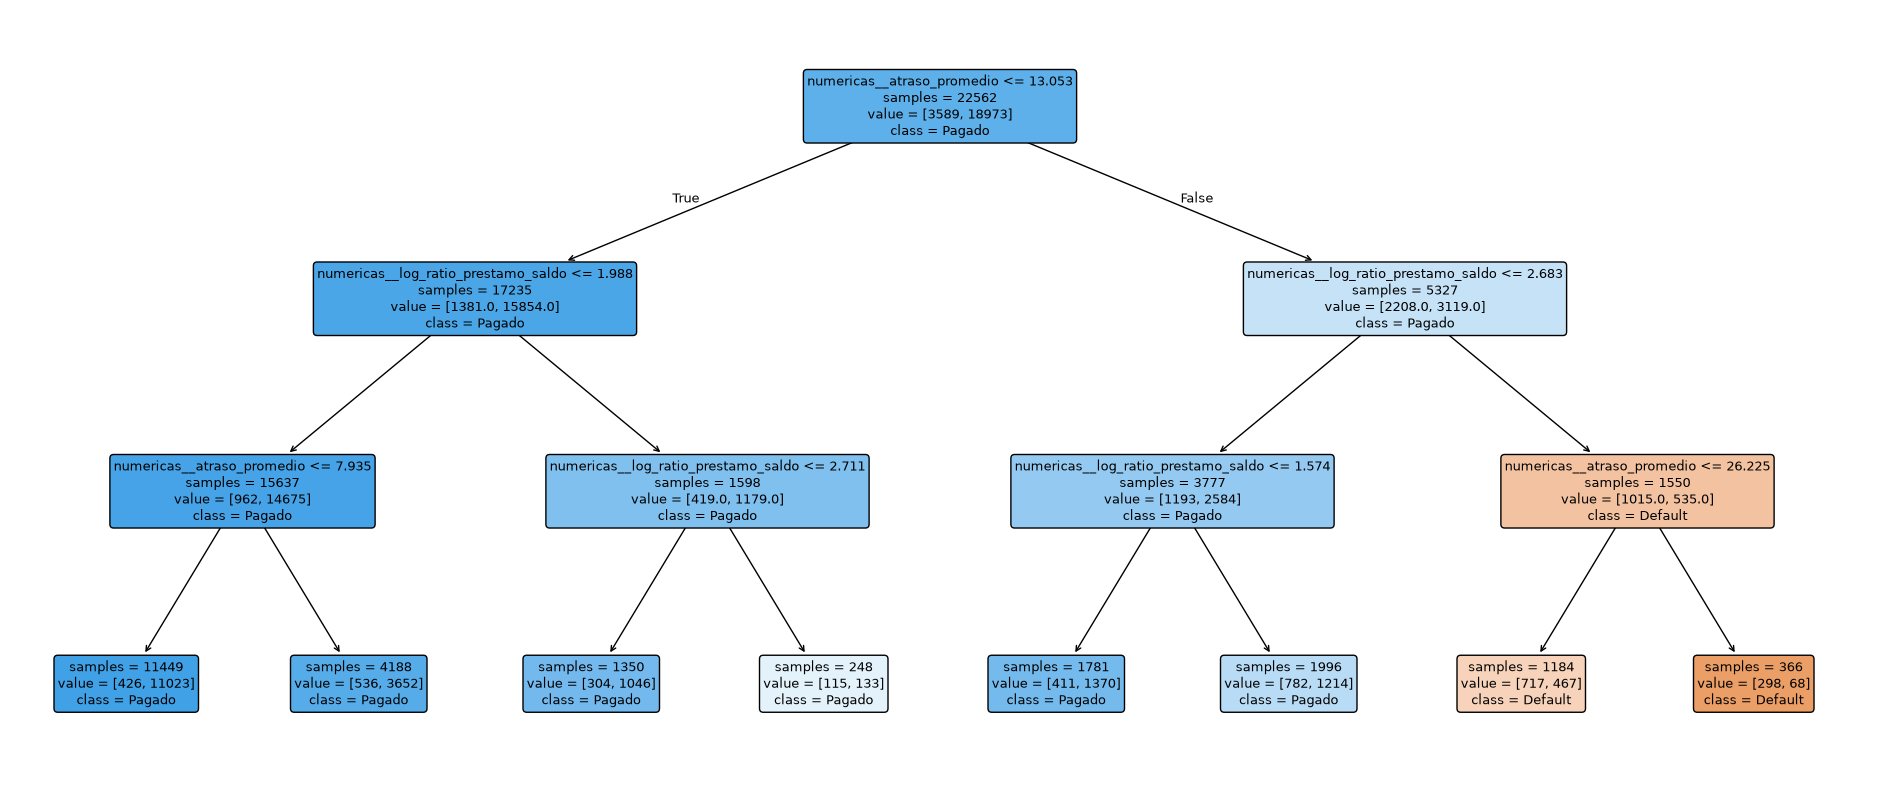

In [97]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Recuperamos las partes del pipeline entrenado
preparacion_entrenada = arbol_inicial.named_steps["preparacion"]
modelo_arbol = arbol_inicial.named_steps["modelo"]

# Nombres de las columnas después de aplicar OneHotEncoder
nombres_columnas = preparacion_entrenada.get_feature_names_out()    # devuelve los nombres de las columnas que salen de la preparacion

plt.figure(figsize=(24, 10))

plot_tree(
    modelo_arbol,
    feature_names=nombres_columnas,
    class_names=["Default", "Pagado"],
    filled=True,
    impurity=False,
    rounded=True,
    fontsize=9
)

plt.show()

uso el atraso promedio y la relación entre el préstamo y el saldo (no uso motivo del prestamo [que bueno mucho laburo el one hot pero vemos si despues se puede usar y ver si genera alguna mejoria])

muestra como que tener un atraso promedio menor al 13... es una condicion (que a pesar que se sigue preguntando cosas despues) que lleva a predecir que las solicitudes seran pagadas

Ahora lo evaluamos

In [98]:
from sklearn.metrics import roc_auc_score, brier_score_loss

# Buscamos la columna correspondiente a Estado_Final = 1 (Pagado)
indice_pagado = list(modelo_arbol.classes_).index(1)

probabilidades_train = arbol_inicial.predict_proba(
    X_train
)[:, indice_pagado]

probabilidades_validacion = arbol_inicial.predict_proba(
    X_validacion
)[:, indice_pagado]

resultados_iniciales = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación"],
    "ROC AUC": [
        roc_auc_score(y_train, probabilidades_train),
        roc_auc_score(y_validacion, probabilidades_validacion)
    ],
    "Brier score": [
        brier_score_loss(y_train, probabilidades_train),
        brier_score_loss(y_validacion, probabilidades_validacion)
    ]
})

resultados_iniciales.round(4)

# ROC AUC: más alto es mejor. Un valor de 0,5 equivale a una separación al azar; 1 representa una separación perfecta
# Brier score: más bajo es mejor. Penaliza las diferencias entre las probabilidades y lo que realmente ocurrió

,Conjunto,ROC AUC,Brier score
0,Entrenamiento,0.8163,0.1022
1,Validación,0.8142,0.1023


el ROC AUC de 0.8142 indica que logra separar pagadores de morosos mejor que el azar y el Brier de 0.1023 vamos a usarlo de referencia para comparar las probabilidades de los siguientes arboles

vemos de sacarle el max depth y ver que hace

In [99]:
from sklearn.base import clone                      # apra hacer una preparacion nueva sin entrenar

# Creamos una copia sin entrenar de la preparación
arbol_libre = Pipeline([
    ("preparacion", clone(preparacion_arbol)),
    (
        "modelo",
        DecisionTreeClassifier(random_state=42)
    )
])

arbol_libre.fit(X_train, y_train)

indice_pagado_libre = list(
    arbol_libre.named_steps["modelo"].classes_
).index(1)

probabilidades_train_libre = arbol_libre.predict_proba(
    X_train
)[:, indice_pagado_libre]

probabilidades_validacion_libre = arbol_libre.predict_proba(
    X_validacion
)[:, indice_pagado_libre]

resultados_libre = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación"],
    "ROC AUC": [
        roc_auc_score(y_train, probabilidades_train_libre),
        roc_auc_score(y_validacion, probabilidades_validacion_libre)
    ],
    "Brier score": [
        brier_score_loss(y_train, probabilidades_train_libre),
        brier_score_loss(y_validacion, probabilidades_validacion_libre)
    ]
})

resultados_libre.round(4)

,Conjunto,ROC AUC,Brier score
0,Entrenamiento,1.0000,0.0000
1,Validación,0.6282,0.2092


el árbol libre logra resultados perfectos con los datos conocidos, pero empeora al evaluar solicitudes nuevas (onda aprendio detalles de los ejemplos conocidos que no le sirvieron para predecir otras solicitudes)

vemos algun punto intermedio para probar si mejor, controlando profundidad y la cantidad minima de sooicitudes por hoja (la pasamos varias para que vaya probando)

In [100]:
from sklearn.model_selection import GridSearchCV, GroupKFold

# Pipeline nuevo, sin entrenar
arbol_busqueda = Pipeline([
    ("preparacion", clone(preparacion_arbol)),
    (
        "modelo",
        DecisionTreeClassifier(random_state=42)
    )
])

# Combinaciones que vamos a comparar
parametros = {
    "modelo__max_depth": [3, 5, 8, None],       # cambia max_depth del paso llamado "modelo" dentro del pipeline.
    "modelo__min_samples_leaf": [20, 50, 100]
    # van a ser 12 configuraciones en total
}

# Usuarios correspondientes a las filas de entrenamiento
grupos_train = grupos.iloc[indices_train]

# Tres divisiones internas, sin compartir usuarios
divisiones = GroupKFold(n_splits=3)

busqueda_arbol = GridSearchCV(
    estimator=arbol_busqueda,
    param_grid=parametros,
    scoring={
        "auc": "roc_auc",
        "brier": "neg_brier_score"  # devuelve el brier con signo negativo porque la búsqueda elige el valor más alto
    },
    refit="brier",
    cv=divisiones,
    return_train_score=True
)

busqueda_arbol.fit(
    X_train,
    y_train,
    groups=grupos_train
)

print("Mejores parámetros:")
print(busqueda_arbol.best_params_)

print(
    "\nBrier promedio en las pruebas internas:",
    round(-busqueda_arbol.best_score_, 4)
)

Mejores parámetros:
{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 100}

Brier promedio en las pruebas internas: 0.1019


parece que la mejor profundidad es 5 y que haya al menos 100 solis por hoja.

ahora vamos a evaluarla a ver si funciona bien

In [101]:
# La búsqueda ya entrenó este modelo con todo X_train
arbol_ajustado = busqueda_arbol.best_estimator_

indice_pagado_ajustado = list(
    arbol_ajustado.named_steps["modelo"].classes_
).index(1)

probabilidades_train_ajustado = arbol_ajustado.predict_proba(
    X_train
)[:, indice_pagado_ajustado]

probabilidades_validacion_ajustado = arbol_ajustado.predict_proba(
    X_validacion
)[:, indice_pagado_ajustado]

comparacion_arboles = pd.DataFrame({
    "Modelo": [
        "Profundidad 3",
        "Sin límite",
        "Profundidad 5, mínimo 100 por hoja"
    ],
    "AUC entrenamiento": [
        roc_auc_score(y_train, probabilidades_train),
        roc_auc_score(y_train, probabilidades_train_libre),
        roc_auc_score(y_train, probabilidades_train_ajustado)
    ],
    "AUC validación": [
        roc_auc_score(y_validacion, probabilidades_validacion),
        roc_auc_score(y_validacion, probabilidades_validacion_libre),
        roc_auc_score(y_validacion, probabilidades_validacion_ajustado)
    ],
    "Brier entrenamiento": [
        brier_score_loss(y_train, probabilidades_train),
        brier_score_loss(y_train, probabilidades_train_libre),
        brier_score_loss(y_train, probabilidades_train_ajustado)
    ],
    "Brier validación": [
        brier_score_loss(y_validacion, probabilidades_validacion),
        brier_score_loss(y_validacion, probabilidades_validacion_libre),
        brier_score_loss(y_validacion, probabilidades_validacion_ajustado)
    ]
})

comparacion_arboles.round(4)

,Modelo,AUC entrenamiento,AUC validación,Brier entrenamiento,Brier validación
0,Profundidad 3,0.8163,0.8142,0.1022,0.1023
1,Sin límite,1.0000,0.6282,0.0000,0.2092
2,"Profundidad 5, mínimo 100 por hoja",0.8387,0.8348,0.0986,0.1001


El arbol anterior tuvo mejores resultados en validacion que los otros dos. Permitir más profundidad, pero exigir al menos cien solicitudes por hoja, permitio aprender más relaciones sin sobreajustar como en el arbol sin limite.

guardamos este modelo como referencia para la futura comparación con ensembles. 

ahora usamos las probabilidades de pago para calcular la ganancia esperada de cada prestamo

In [102]:
# Conservamos los datos originales de las solicitudes de validación
evaluacion_prestamos = validacion_completa.copy()

evaluacion_prestamos["probabilidad_pago"] = (
    probabilidades_validacion_ajustado
)

# Si paga, ganamos los intereses.
# Si no paga, perdemos el capital prestado.
evaluacion_prestamos["ganancia_esperada"] = (
    evaluacion_prestamos["probabilidad_pago"]
    * evaluacion_prestamos["Monto_Solicitado"]
    * evaluacion_prestamos["Tasa_Interes"]
    - (1 - evaluacion_prestamos["probabilidad_pago"])
    * evaluacion_prestamos["Monto_Solicitado"]
)                                                       # Ej Ganancia esperada = 0,90 × 200 − 0,10 × 1.000  = 80 USD

evaluacion_prestamos[[
    "ID_Solicitud",
    "Monto_Solicitado",
    "Tasa_Interes",
    "probabilidad_pago",
    "ganancia_esperada"
]].head(10)

,ID_Solicitud,Monto_Solicitado,Tasa_Interes,probabilidad_pago,ganancia_esperada
2,3,8600,0.2368,0.513953,-3133.344000
7,8,8000,0.2993,0.954928,1925.905498
8,9,9600,0.2649,0.917208,1537.690909
9,10,23400,0.2609,0.430556,-10696.432500
13,14,12700,0.2551,0.954928,2521.335592
15,16,10700,0.2531,0.960320,2176.138500
17,18,5400,0.2180,0.960320,916.219003
25,26,28400,0.3374,0.590643,-5966.092632
26,27,15900,0.2718,0.917208,2647.427435
28,29,6600,0.2237,0.984902,1354.480256


Seleccionamos los prestamos

sacamos primero las ganancias engativas, o sea que no pagarian y despues ordenamos de mayor a menor segun la ganancia que esperamos de la solicitud que supuestmante se pagaria

In [103]:
presupuesto = 2_000_000

evaluacion_prestamos["retorno_esperado"] = (
    evaluacion_prestamos["ganancia_esperada"]
    / evaluacion_prestamos["Monto_Solicitado"]
)

# Solo consideramos préstamos con ganancia esperada positiva
candidatos = evaluacion_prestamos.loc[
    evaluacion_prestamos["ganancia_esperada"] > 0
].copy()

# Ordenamos por ganancia esperada por dólar prestado.
# Ante un empate, priorizamos el menor monto y luego el ID.
candidatos = candidatos.sort_values(
    ["retorno_esperado", "Monto_Solicitado", "ID_Solicitud"],
    ascending=[False, True, True]
)

capital_utilizado = 0
ids_aprobados = []

for _, solicitud in candidatos.iterrows():
    monto = solicitud["Monto_Solicitado"]

    if capital_utilizado + monto <= presupuesto:
        ids_aprobados.append(solicitud["ID_Solicitud"])
        capital_utilizado += monto

evaluacion_prestamos["aprobado"] = (
    evaluacion_prestamos["ID_Solicitud"].isin(ids_aprobados)
)

prestamos_aprobados = evaluacion_prestamos.loc[
    evaluacion_prestamos["aprobado"]
].copy()

ganancia_esperada_total = (
    prestamos_aprobados["ganancia_esperada"].sum()
)

roi_esperado = (
    ganancia_esperada_total / capital_utilizado
    if capital_utilizado > 0
    else 0
)

print("Cantidad de préstamos aprobados:", len(prestamos_aprobados))
print(f"Capital utilizado: USD {capital_utilizado:,.2f}")
print(f"Presupuesto restante: USD {presupuesto - capital_utilizado:,.2f}")
print(f"Ganancia esperada total: USD {ganancia_esperada_total:,.2f}")
print(f"ROI esperado: {roi_esperado:.2%}")

Cantidad de préstamos aprobados: 86
Capital utilizado: USD 2,000,000.00
Presupuesto restante: USD 0.00
Ganancia esperada total: USD 574,898.96
ROI esperado: 28.74%


Con esto elegimos los prestamos, vamos a ver si en verdad nos van a pagar

In [104]:
prestamos_aprobados["ganancia_real"] = np.where(
    prestamos_aprobados["Estado_Final"] == 1,
    prestamos_aprobados["Monto_Solicitado"]
    * prestamos_aprobados["Tasa_Interes"],
    -prestamos_aprobados["Monto_Solicitado"]
)

ganancia_real_total = prestamos_aprobados["ganancia_real"].sum()

roi_real = (
    ganancia_real_total / capital_utilizado
    if capital_utilizado > 0
    else 0
)

cantidad_defaults = (
    prestamos_aprobados["Estado_Final"].eq(0).sum()
)

capital_en_default = prestamos_aprobados.loc[
    prestamos_aprobados["Estado_Final"] == 0,
    "Monto_Solicitado"
].sum()

print(f"Ganancia esperada: USD {ganancia_esperada_total:,.2f}")
print(f"Ganancia real: USD {ganancia_real_total:,.2f}")
print(f"ROI esperado: {roi_esperado:.2%}")
print(f"ROI real: {roi_real:.2%}")
print(f"Préstamos en default: {cantidad_defaults} de {len(prestamos_aprobados)}")
print(f"Capital perdido por defaults: USD {capital_en_default:,.2f}")

Ganancia esperada: USD 574,898.96
Ganancia real: USD 637,569.86
ROI esperado: 28.74%
ROI real: 31.88%
Préstamos en default: 1 de 86
Capital perdido por defaults: USD 6,900.00


Le fue mejor de lo que esperaba

preparamos las solicitudes nuevas (test) de la misma manera que las de entrenamiento

In [105]:
solicitudes_test = pd.read_csv("data/solicitudes_test.csv")

solicitudes_test["Fecha_Solicitud"] = pd.to_datetime(
    solicitudes_test["Fecha_Solicitud"]
)

banco_test = comportamiento_bancario.copy()

banco_test["Mes_Referencia"] = pd.to_datetime(
    banco_test["Mes_Referencia"]
)

historial_test = solicitudes_test[[
    "ID_Solicitud",
    "ID_Usuario",
    "Fecha_Solicitud"
]].merge(
    banco_test,
    on="ID_Usuario",
    how="left"
)

# Conservamos únicamente los meses anteriores a la solicitud
historial_test = historial_test.loc[
    historial_test["Mes_Referencia"]
    < historial_test["Fecha_Solicitud"]
].copy()

historial_test = historial_test.sort_values(
    ["ID_Solicitud", "Mes_Referencia"]
)

print("Solicitudes de test:", len(solicitudes_test))
print(
    "Solicitudes con historial anterior:",
    historial_test["ID_Solicitud"].nunique()
)
print(
    "Solicitudes sin historial anterior:",
    len(solicitudes_test)
    - historial_test["ID_Solicitud"].nunique()
)

Solicitudes de test: 3061
Solicitudes con historial anterior: 3061
Solicitudes sin historial anterior: 0


In [106]:
resumen_historial_test = historial_test.groupby("ID_Solicitud").agg(
    meses_historial=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

datos_test = solicitudes_test.merge(
    resumen_historial_test,
    on="ID_Solicitud",
    how="left",
    validate="one_to_one"
)

# Evitamos dividir por cero
saldo_inicial_seguro_test = datos_test["saldo_inicial"].mask(
    datos_test["saldo_inicial"].eq(0)
)

saldo_promedio_seguro_test = datos_test["saldo_promedio"].mask(
    datos_test["saldo_promedio"].eq(0)
)

datos_test["ratio_tendencia_saldo"] = (
    datos_test["saldo_final"] / saldo_inicial_seguro_test
)

datos_test["ratio_prestamo_ingreso"] = (
    datos_test["Monto_Solicitado"] / datos_test["Ingreso_Mensual"]
)

datos_test["ratio_prestamo_saldo"] = (
    datos_test["Monto_Solicitado"] / saldo_promedio_seguro_test
)

# Las mismas transformaciones usadas en entrenamiento
datos_test["log_ratio_prestamo_ingreso"] = np.log1p(
    datos_test["ratio_prestamo_ingreso"]
)

datos_test["log_ratio_prestamo_saldo"] = np.log1p(
    datos_test["ratio_prestamo_saldo"]
)

datos_test["log_ratio_tendencia_saldo"] = np.log(
    datos_test["ratio_tendencia_saldo"]
)

datos_test = datos_test.drop(columns="saldo_inicial")

# Seleccionamos las mismas columnas y en el mismo orden
X_test = datos_test[X.columns].copy()

print("Solicitudes preparadas:", len(X_test))
print("IDs repetidos:", datos_test["ID_Solicitud"].duplicated().sum())

print("\nValores faltantes:")
print(X_test.isna().sum())

print("\nValores infinitos:")
print(
    np.isinf(
        X_test.select_dtypes(include="number")
    ).sum()
)

Solicitudes preparadas: 3061
IDs repetidos: 0

Valores faltantes:
Monto_Solicitado              0
Tasa_Interes                  0
Ingreso_Mensual               0
Motivo_Prestamo               0
meses_historial               0
saldo_promedio                0
saldo_final                   0
atraso_promedio               0
atraso_maximo                 0
log_ratio_prestamo_ingreso    0
log_ratio_prestamo_saldo      0
log_ratio_tendencia_saldo     0
dtype: int64

Valores infinitos:
Monto_Solicitado              0
Tasa_Interes                  0
Ingreso_Mensual               0
meses_historial               0
saldo_promedio                0
saldo_final                   0
atraso_promedio               0
atraso_maximo                 0
log_ratio_prestamo_ingreso    0
log_ratio_prestamo_saldo      0
log_ratio_tendencia_saldo     0
dtype: int64


modelo final

In [107]:
# Copiamos la configuración elegida, sin conservar su entrenamiento
arbol_final = clone(arbol_ajustado)

# Entrenamos con todo el histórico
arbol_final.fit(X, y)

# Identificamos la columna de probabilidad de pago
indice_pagado_final = list(
    arbol_final.named_steps["modelo"].classes_
).index(1)

probabilidades_test = arbol_final.predict_proba(
    X_test
)[:, indice_pagado_final]

# Guardamos las predicciones junto a cada solicitud
resultado_test = datos_test[[
    "ID_Solicitud",
    "Monto_Solicitado",
    "Tasa_Interes"
]].copy()

resultado_test["probabilidad_pago"] = probabilidades_test

resultado_test["ganancia_esperada"] = (
    resultado_test["probabilidad_pago"]
    * resultado_test["Monto_Solicitado"]
    * resultado_test["Tasa_Interes"]
    - (1 - resultado_test["probabilidad_pago"])
    * resultado_test["Monto_Solicitado"]
)

resultado_test["retorno_esperado"] = (
    resultado_test["ganancia_esperada"]
    / resultado_test["Monto_Solicitado"]
)

print("Solicitudes con predicción:", len(resultado_test))
print(
    "Solicitudes con ganancia esperada positiva:",
    resultado_test["ganancia_esperada"].gt(0).sum()
)

resultado_test.head(10)

Solicitudes con predicción: 3061
Solicitudes con ganancia esperada positiva: 2607


,ID_Solicitud,Monto_Solicitado,Tasa_Interes,probabilidad_pago,ganancia_esperada,retorno_esperado
0,32417,2300,0.2771,0.751527,-92.515743,-0.040224
1,32418,10900,0.3291,0.983386,3346.497643,0.307018
2,32419,1300,0.2485,0.728758,-117.189052,-0.090145
3,32420,1600,0.2699,0.905534,239.899569,0.149937
4,32421,900,0.2317,0.983386,190.112716,0.211236
5,32422,500,0.2436,0.905534,63.060847,0.126122
6,32423,6200,0.2713,0.983386,1551.106268,0.250178
7,32424,1800,0.2749,0.905534,278.036819,0.154465
8,32425,900,0.2033,0.837912,7.433654,0.008260
9,32426,1900,0.2480,0.728758,-171.968627,-0.090510


elegimos los prestamos

In [108]:
presupuesto_test = 2_000_000

candidatos_test = resultado_test.loc[
    resultado_test["ganancia_esperada"] > 0
].sort_values(
    ["retorno_esperado", "Monto_Solicitado", "ID_Solicitud"],
    ascending=[False, True, True]
)

capital_test = 0
ids_aprobados_test = []

for _, solicitud in candidatos_test.iterrows():
    monto = solicitud["Monto_Solicitado"]

    if capital_test + monto <= presupuesto_test:
        ids_aprobados_test.append(solicitud["ID_Solicitud"])
        capital_test += monto

# Conservamos todas las solicitudes en el orden original
resultado_test["aprobado"] = (
    resultado_test["ID_Solicitud"]
    .isin(ids_aprobados_test)
    .astype(int)
)

seleccion_test = resultado_test.loc[
    resultado_test["aprobado"] == 1
]

# Comprobaciones antes de exportar
assert len(resultado_test) == len(solicitudes_test)
assert resultado_test["ID_Solicitud"].is_unique
assert resultado_test["ID_Solicitud"].tolist() == (
    solicitudes_test["ID_Solicitud"].tolist()
)
assert resultado_test["aprobado"].isin([0, 1]).all()
assert seleccion_test["Monto_Solicitado"].sum() <= presupuesto_test

print("Solicitudes totales:", len(resultado_test))
print("Préstamos aprobados:", len(seleccion_test))
print(f"Capital aprobado: USD {capital_test:,.2f}")
print(f"Presupuesto restante: USD {presupuesto_test - capital_test:,.2f}")
print(
    "Ganancia esperada: "
    f"USD {seleccion_test['ganancia_esperada'].sum():,.2f}"
)

Solicitudes totales: 3061
Préstamos aprobados: 618
Capital aprobado: USD 1,999,700.00
Presupuesto restante: USD 300.00
Ganancia esperada: USD 534,862.98


archivo para entregar

In [109]:
entrega = resultado_test[["ID_Solicitud", "aprobado"]].rename(
    columns={"aprobado": "Desicion_Aprobacion"}
)

assert len(entrega) == 3061
assert entrega["ID_Solicitud"].is_unique
assert entrega["Desicion_Aprobacion"].isin([0, 1]).all()
assert not entrega.isna().any().any()

entrega.to_csv("submission_arbol.csv", index=False)

print("Archivo generado: submission_arbol.csv")
print("Aprobados:", entrega["Desicion_Aprobacion"].sum())

entrega.head()

Archivo generado: submission_arbol.csv
Aprobados: 618


,ID_Solicitud,Desicion_Aprobacion
0,32417,0
1,32418,1
2,32419,0
3,32420,0
4,32421,0
